# 1. Exploratory Data Analysis (EDA) and Image Quality Assessment

## check consistency of the 20k dataset with the original images

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive/NIH_ChestXray'))

['Training_Data', 'images_tar', 'Data_Entry_2017_v2020.csv', 'train_val_list.txt', 'test_list.txt']


In [ ]:
import os

for folder in ['train', 'validation', 'test']:
    path = f'/content/drive/MyDrive/NIH_ChestXray/Training_Data/{folder}'
    print(folder, os.path.isdir(path))

train True
validation True
test True


In [ ]:
import pandas as pd

csv_url = (
    "Data/splits/balanced_20k_metadata.csv"
)

df = pd.read_csv(csv_url)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Shape: (20000, 14)
Columns: ['image_name', 'finding_labels', 'follow_up', 'patient_id', 'patient_age', 'patient_sex', 'view_position', 'image_width', 'image_height', 'pixel_spacing_x', 'pixel_spacing_y', 'label', 'binary_label', 'split']


,image_name,finding_labels,follow_up,patient_id,patient_age,patient_sex,view_position,image_width,image_height,pixel_spacing_x,pixel_spacing_y,label,binary_label,split
0,00004338_003.png,Edema,3,4338,49,M,AP,2500,2048,0.171,0.171,1,Abnormal,train
1,00001922_002.png,No Finding,2,1922,44,M,PA,2992,2991,0.143,0.143,0,Normal,train
2,00025082_006.png,Effusion|Mass,7,25082,60,F,PA,2722,2837,0.143,0.143,1,Abnormal,train
3,00006960_003.png,No Finding,3,6960,16,M,PA,2048,2500,0.171,0.171,0,Normal,train
4,00012094_058.png,Emphysema,58,12094,63,F,AP,2500,2048,0.168,0.168,1,Abnormal,train


In [ ]:
print("Rows:", len(df))
print("Unique image names:", df["image_name"].nunique())
print("\nRows per split:")
print(df["split"].value_counts())

print("\nColumns we'll use:")
print(df[[
    "image_name", "split", "binary_label",
    "finding_labels", "patient_id",
    "patient_age", "patient_sex", "view_position"
]].head())

Rows: 20000
Unique image names: 20000

Rows per split:
split
train         14000
test           3000
validation     3000
Name: count, dtype: int64

Columns we'll use:
         image_name  split binary_label finding_labels  patient_id  \
0  00004338_003.png  train     Abnormal          Edema        4338   
1  00001922_002.png  train       Normal     No Finding        1922   
2  00025082_006.png  train     Abnormal  Effusion|Mass       25082   
3  00006960_003.png  train       Normal     No Finding        6960   
4  00012094_058.png  train     Abnormal      Emphysema       12094   

   patient_age patient_sex view_position  
0           49           M            AP  
1           44           M            PA  
2           60           F            PA  
3           16           M            PA  
4           63           F            AP  


In [ ]:
from pathlib import Path

data_root = Path(
    "/content/drive/MyDrive/NIH_ChestXray/Training_Data"
)

for split in ["train", "validation", "test"]:
    expected = set(df.loc[df["split"] == split, "image_name"].dropna())

    folder = data_root / split
    actual = {
        path.name
        for path in folder.iterdir()
        if path.is_file() and path.suffix.lower() == ".png"
    }

    missing = expected - actual
    extra = actual - expected

    print(
        f"{split}: expected={len(expected)}, found={len(expected & actual)}, "
        f"missing={len(missing)}, extra={len(extra)}"
    )

train: expected=14000, found=14000, missing=0, extra=0
validation: expected=3000, found=3000, missing=0, extra=0
test: expected=3000, found=3000, missing=0, extra=0


# 2. Analyze Image Characteristics and Quality

## 2.1 Image Resolution
### - Width
### - Height
### - Variation in image dimensions

In [ ]:

import pandas as pd
df = pd.read_csv("../Data/splits/balanced_20k_metadata.csv")

In [ ]:
print("Rows:", len(df))
print("Available dimension columns:",
      [c for c in ["image_width", "image_height"] if c in df.columns])

if {"image_width", "image_height"}.issubset(df.columns):
    df["aspect_ratio"] = df["image_width"] / df["image_height"]

    display(
        df[["image_width", "image_height", "aspect_ratio"]]
        .describe(percentiles=[.25, .5, .75])
        .T
        .round(2)
    )

    print("Most common dimensions:")
    display(
        df.groupby(["image_width", "image_height"])
          .size()
          .sort_values(ascending=False)
          .head(10)
          .rename("image_count")
          .to_frame()
    )
else:
    print("The metadata CSV does not contain both dimension columns.")

Rows: 20000
Available dimension columns: ['image_width', 'image_height']


,count,mean,std,min,25%,50%,75%,max
image_width,20000.0,2644.38,340.37,1411.00,2500.0,2506.00,2992.00,3550.00
image_height,20000.0,2484.68,398.46,1306.00,2048.0,2544.00,2991.00,3166.00
aspect_ratio,20000.0,1.08,0.15,0.68,1.0,1.08,1.22,1.69


Most common dimensions:


,,image_count
image_width,image_height,
2500,2048,6650
2992,2991,3801
3056,2544,2776
2048,2500,1605
2021,2021,765
2544,3056,406
2990,2991,84
2020,2021,71
2021,2020,54


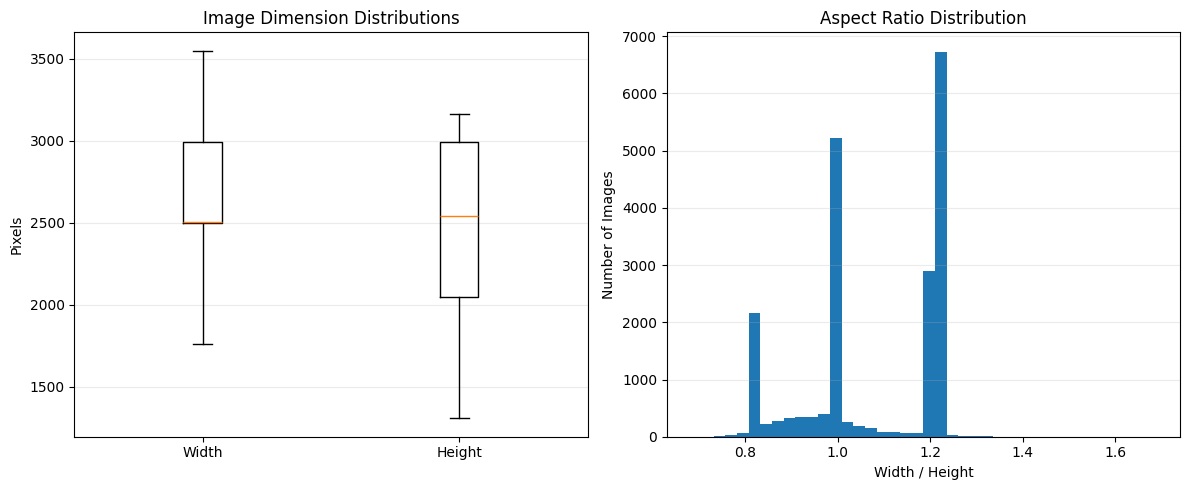

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot(
    [df["image_width"].dropna(), df["image_height"].dropna()],
    tick_labels=["Width", "Height"],
    showfliers=False
)
axes[0].set_title("Image Dimension Distributions")
axes[0].set_ylabel("Pixels")
axes[0].grid(axis="y", alpha=0.25)


axes[1].hist(df["aspect_ratio"].dropna(), bins=40)
axes[1].set_title("Aspect Ratio Distribution")
axes[1].set_xlabel("Width / Height")
axes[1].set_ylabel("Number of Images")
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### Initial observations: image dimensions and aspect ratio

The metadata shows that image dimensions vary across the dataset. Widths have a median of approximately 2,500 pixels, while heights have a median of approximately 2,540 pixels. The box plots also show a broad spread in both dimensions, so the images do not all share one fixed resolution.

The aspect-ratio histogram has several prominent peaks, including values near 0.82, 1.00, and 1.22. This suggests that the dataset contains groups of images with different width-to-height proportions, rather than one uniform image shape.

These are descriptive observations from the recorded metadata. The plots alone do not explain why the dimensions or aspect ratios differ, or whether those differences are associated with the image label or acquisition view. The next step is to compare these measurements across Normal and Abnormal images and across AP/PA views.

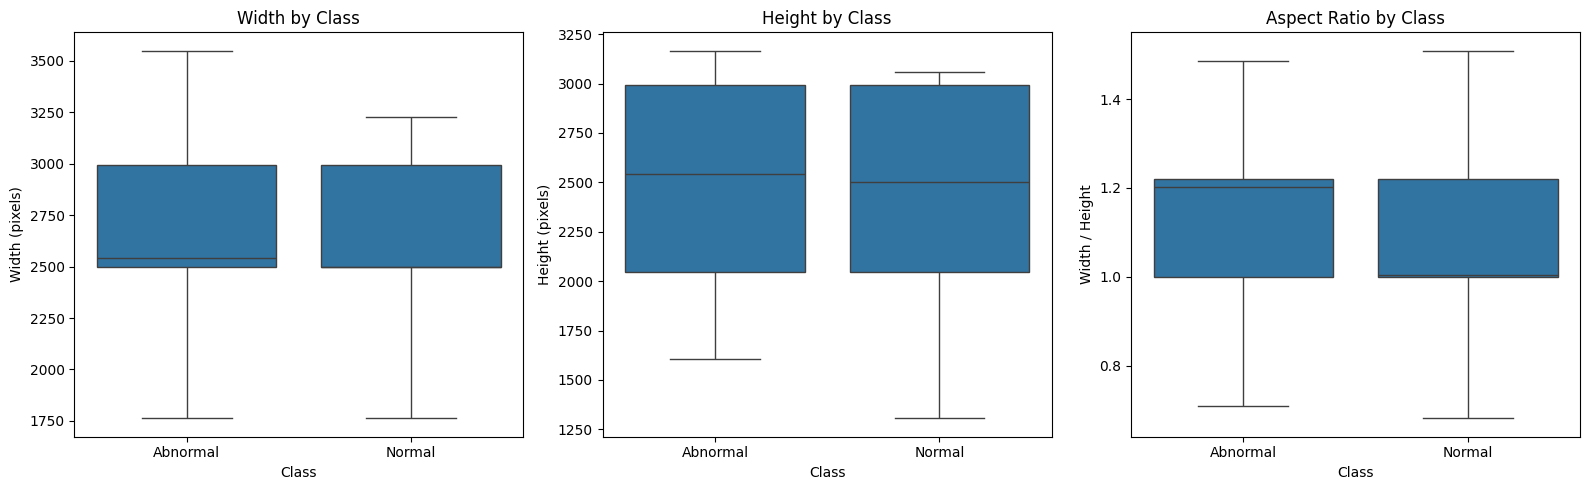

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt


fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(data=df, x="binary_label", y="image_width", ax=axes[0], showfliers=False)
axes[0].set_title("Width by Class")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Width (pixels)")

sns.boxplot(data=df, x="binary_label", y="image_height", ax=axes[1], showfliers=False)
axes[1].set_title("Height by Class")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Height (pixels)")

sns.boxplot(data=df, x="binary_label", y="aspect_ratio", ax=axes[2], showfliers=False)
axes[2].set_title("Aspect Ratio by Class")
axes[2].set_xlabel("Class")
axes[2].set_ylabel("Width / Height")

plt.tight_layout()
plt.show()

In [ ]:
df.groupby("binary_label")[[
    "image_width", "image_height", "aspect_ratio"
]].agg(["count", "median", "mean", "std", "min", "max"]).round(2)

image_width                                      image_height  \
                   count  median     mean     std   min   max        count   
binary_label                                                                 
Abnormal           10000  2544.0  2666.12  333.30  1456  3550        10000   
Normal             10000  2500.0  2622.64  345.94  1411  3226        10000   

                                                  aspect_ratio               \
              median     mean     std   min   max        count median  mean   
binary_label                                                                  
Abnormal      2544.0  2477.92  396.28  1605  3166        10000    1.2  1.09   
Normal        2500.0  2491.43  400.54  1306  3056        10000    1.0  1.07   

                                
               std   min   max  
binary_label                    
Abnormal      0.14  0.71  1.49  
Normal        0.15  0.68  1.69

### Image dimensions by class

The metadata reports similar image dimensions for the Normal and Abnormal groups. Median width is 2,544 pixels for Abnormal images and 2,500 pixels for Normal images. Median height shows the same values. The box plots show substantial overlap between the groups.

The aspect-ratio medians differ: 1.20 for Abnormal images and 1.00 for Normal images. However, the means are close (1.09 and 1.07), and the distributions overlap. This difference should be investigated further before drawing a conclusion, particularly in relation to AP/PA view position.

These measurements come from the recorded metadata and do not establish that image dimensions cause or predict the class. The next check is to compare aspect ratio across view positions and classes.

image_count  median_aspect_ratio  \
view_position binary_label                                     
AP            Abnormal             4582                1.221   
              Normal               3434                1.221   
PA            Abnormal             5418                1.000   
              Normal               6566                1.000   

                            mean_aspect_ratio  std_aspect_ratio  
view_position binary_label                                       
AP            Abnormal                  1.197             0.079  
              Normal                    1.195             0.085  
PA            Abnormal                  1.001             0.120  
              Normal                    1.001             0.129

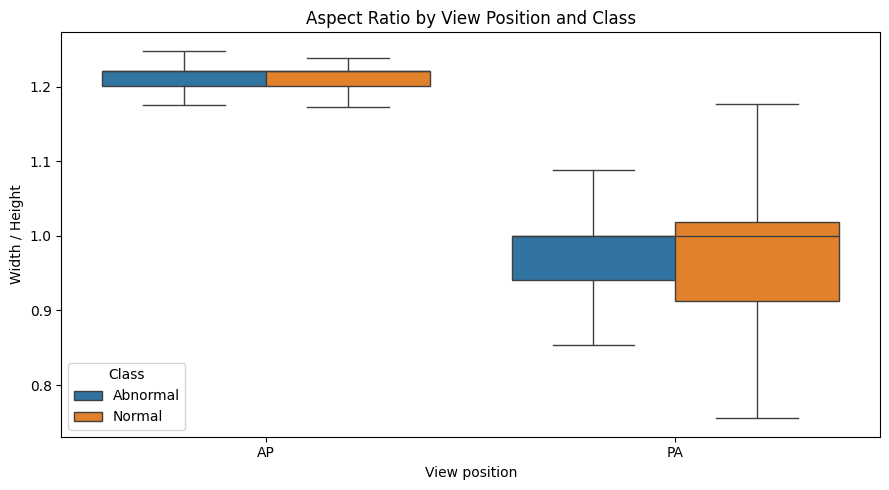

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

aspect_by_view = (
    df.groupby(["view_position", "binary_label"], dropna=False)
      .agg(
          image_count=("aspect_ratio", "count"),
          median_aspect_ratio=("aspect_ratio", "median"),
          mean_aspect_ratio=("aspect_ratio", "mean"),
          std_aspect_ratio=("aspect_ratio", "std")
      )
      .round(3)
)

display(aspect_by_view)


plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df,
    x="view_position",
    y="aspect_ratio",
    hue="binary_label",
    showfliers=False
)
plt.title("Aspect Ratio by View Position and Class")
plt.xlabel("View position")
plt.ylabel("Width / Height")
plt.legend(title="Class")
plt.tight_layout()
plt.show()

### Aspect ratio by view position and class

The aspect-ratio distributions are nearly identical between classes within each view position. For AP images, the median aspect ratio is 1.221 for both Abnormal and Normal images. For PA images, it is 1.000 for both classes. The corresponding means are also very similar within each view.

However, AP images make up 45.8% of the Abnormal group (4,582 of 10,000 images), compared with 34.3% of the Normal group (3,434 of 10,000 images). Because AP and PA images have different aspect-ratio distributions, combining them can make the overall class medians appear different.

This suggests that the overall class difference in aspect ratio may be associated with the different AP/PA composition, rather than a clear aspect-ratio difference between classes within the same view. This is a descriptive association and does not establish causation or model behavior.

image_count  median_width  mean_width  \
view_position binary_label                                          
AP            Abnormal             4582        2500.0      2680.8   
              Normal               3434        2500.0      2652.6   
PA            Abnormal             5418        2734.0      2653.7   
              Normal               6566        2614.0      2607.0   

                            median_height  mean_height  
view_position binary_label                              
AP            Abnormal             2048.0       2246.9  
              Normal               2048.0       2227.4  
PA            Abnormal             2976.0       2673.3  
              Normal               2741.0       2629.5

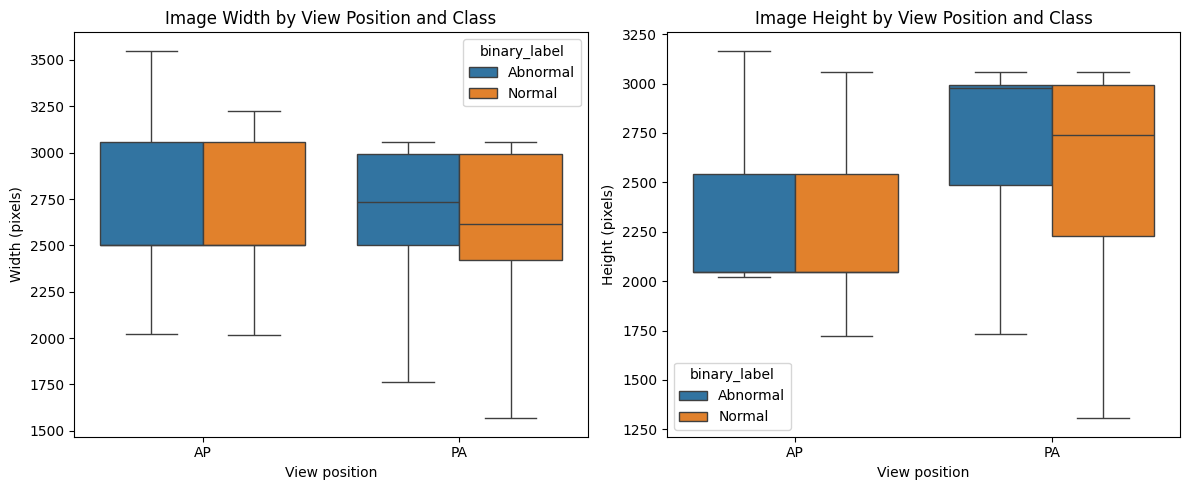

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt


dimension_by_view = (
    df.groupby(["view_position", "binary_label"], dropna=False)
      .agg(
          image_count=("image_width", "count"),
          median_width=("image_width", "median"),
          mean_width=("image_width", "mean"),
          median_height=("image_height", "median"),
          mean_height=("image_height", "mean")
      )
      .round(1)
)

display(dimension_by_view)


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    data=df, x="view_position", y="image_width",
    hue="binary_label", showfliers=False, ax=axes[0]
)
axes[0].set_title("Image Width by View Position and Class")
axes[0].set_xlabel("View position")
axes[0].set_ylabel("Width (pixels)")

sns.boxplot(
    data=df, x="view_position", y="image_height",
    hue="binary_label", showfliers=False, ax=axes[1]
)
axes[1].set_title("Image Height by View Position and Class")
axes[1].set_xlabel("View position")
axes[1].set_ylabel("Height (pixels)")

plt.tight_layout()
plt.show()

### Image dimensions by view position and class

Within AP images, the median width is 2,500 pixels and the median height is 2,048 pixels for both classes. Their mean dimensions are also similar.

Within PA images, Abnormal images have larger median dimensions than Normal images: median width is 2,734 versus 2,614 pixels, and median height is 2,976 versus 2,741 pixels. However, the box plots show overlap between the class distributions, and the mean differences are smaller than the median differences.

This descriptive pattern suggests that image dimensions may differ by class within PA images, while the AP groups have matching medians. These metadata comparisons alone do not establish why the differences occur or whether they affect model performance. The dimension fields are recorded metadata, not measurements made directly from the image pixels.

In [ ]:
df["age_group"] = pd.cut(
    df["patient_age"],
    bins=[0, 18, 40, 60, 120],
    labels=["1–18", "19–40", "41–60", "61–120"]
).astype("object")

df.loc[df["patient_age"].eq(0), "age_group"] = "Recorded age 0"
df.loc[df["patient_age"].isna(), "age_group"] = "Missing"

In [ ]:
age_summary = (
    df.groupby(["age_group", "binary_label"], observed=False)
      .agg(
          image_count=("image_width", "count"),
          median_width=("image_width", "median"),
          median_height=("image_height", "median"),
          median_aspect_ratio=("aspect_ratio", "median")
      )
      .round(2)
)

display(age_summary)

image_count  median_width  median_height  \
age_group      binary_label                                             
19–40          Abnormal             2584        2556.0         2544.0   
               Normal               3168        2500.0         2539.0   
1–18           Abnormal              479        2500.0         2500.0   
               Normal                583        2500.0         2500.0   
41–60          Abnormal             4459        2500.0         2519.0   
               Normal               4383        2500.0         2500.0   
61–120         Abnormal             2478        2629.0         2544.0   
               Normal               1864        2590.0         2544.0   
Recorded age 0 Normal                  2        2778.0         2296.0   

                             median_aspect_ratio  
age_group      binary_label                       
19–40          Abnormal                     1.20  
               Normal                       1.00  
1–18           Abnormal                     1.20  
               Normal                       1.00  
41–60          Abnormal                     1.20  
               Normal                       1.01  
61–120         Abnormal                     1.18  
               Normal                       1.03  
Recorded age 0 Normal                       1.21

In [ ]:
sex_summary = (
    df.groupby(["patient_sex", "binary_label"], dropna=False)
      .agg(
          image_count=("image_width", "count"),
          median_width=("image_width", "median"),
          median_height=("image_height", "median"),
          median_aspect_ratio=("aspect_ratio", "median")
      )
      .round(2)
)

display(sex_summary)

image_count  median_width  median_height  \
patient_sex binary_label                                             
F           Abnormal             4309        2500.0         2525.0   
            Normal               4443        2500.0         2500.0   
M           Abnormal             5691        2678.0         2544.0   
            Normal               5557        2544.0         2544.0   

                          median_aspect_ratio  
patient_sex binary_label                       
F           Abnormal                     1.01  
            Normal                       1.00  
M           Abnormal                     1.20  
            Normal                       1.20

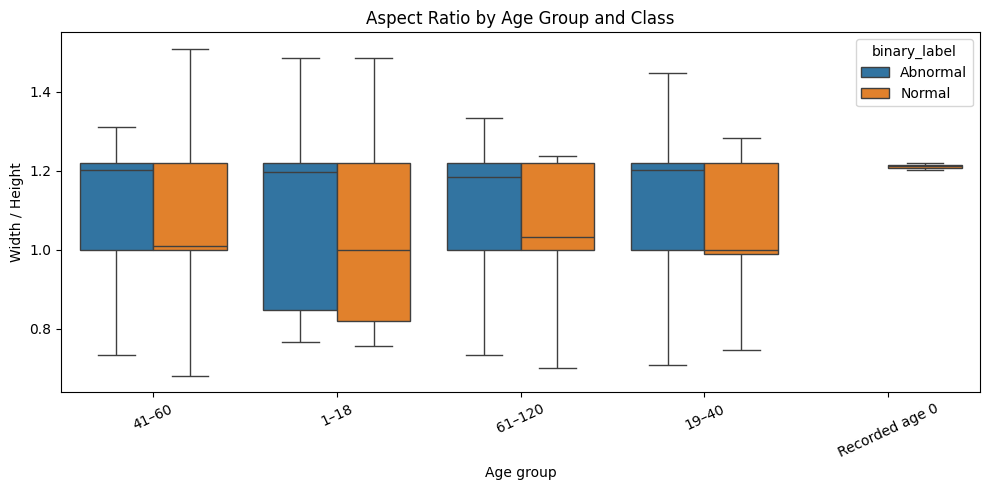

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="age_group",
    y="aspect_ratio",
    hue="binary_label",
    showfliers=False
)

plt.title("Aspect Ratio by Age Group and Class")
plt.xlabel("Age group")
plt.ylabel("Width / Height")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

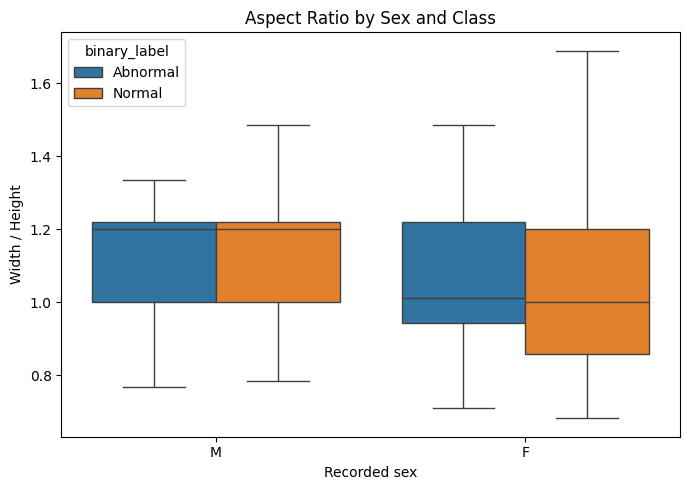

In [ ]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="patient_sex",
    y="aspect_ratio",
    hue="binary_label",
    showfliers=False
)

plt.title("Aspect Ratio by Sex and Class")
plt.xlabel("Recorded sex")
plt.ylabel("Width / Height")
plt.tight_layout()
plt.show()

### Aspect ratio by age and recorded sex

The aspect-ratio medians vary across age and sex groups. Across most age groups, the median is approximately 1.20 for Abnormal images and 1.00 for Normal images. Among males, both classes have a median of 1.20; among females, the medians are 1.01 for Abnormal and 1.00 for Normal.

Earlier analysis showed that AP images have a median aspect ratio of 1.221 for both classes, while PA images have a median of 1.000 for both classes. This suggests that differences in the proportion of AP and PA images across age and sex groups may explain much of the observed pattern.

These are descriptive comparisons based on recorded metadata. They do not show that age or sex causes differences in image dimensions. The AP/PA distribution should be checked within each age and sex group before interpreting these patterns.

## Pixel Intensity and Brightness

This section starts with a two-image pilot sample to confirm that the image-loading and measurement workflow works correctly.

The sample is for demonstrating the analysis process only. Results from two images are not representative of the full dataset and will not be used to draw class or subgroup conclusions.

In [25]:
from pathlib import Path
import pandas as pd


data_root = Path("/content/drive/MyDrive/NIH_ChestXray/Training_Data")
df = pd.read_csv("/content/balanced_20k_metadata.csv")
print("Images folder exists:", data_root.exists())
print("Metadata shape:", df.shape)
print("Metadata columns:", df.columns.tolist())

Images folder exists: True
Metadata shape: (20000, 14)
Metadata columns: ['image_name', 'finding_labels', 'follow_up', 'patient_id', 'patient_age', 'patient_sex', 'view_position', 'image_width', 'image_height', 'pixel_spacing_x', 'pixel_spacing_y', 'label', 'binary_label', 'split']


In [26]:
sample = df.sample(n=2, random_state=7).copy()

sample[["image_name", "split", "binary_label", "patient_age", "patient_sex", "view_position"]]

,image_name,split,binary_label,patient_age,patient_sex,view_position
14356,00030252_001.png,train,Abnormal,62,M,PA
3439,00014626_003.png,train,Normal,44,F,AP


In [27]:
dimension_check = []

for _, row in sample.iterrows():
    image_path = data_root / row["split"] / row["image_name"]

    with Image.open(image_path) as image:
        actual_width, actual_height = image.size

    dimension_check.append({
        "image_name": row["image_name"],
        "metadata_width": row["image_width"],
        "metadata_height": row["image_height"],
        "file_width": actual_width,
        "file_height": actual_height,
    })

pd.DataFrame(dimension_check)

,image_name,metadata_width,metadata_height,file_width,file_height
0,00030252_001.png,2021,2021,1024,1024
1,00014626_003.png,3056,2544,1024,1024


### Measurement approach

Images are converted to grayscale before analysis. Pixel intensity is recorded on a scale from 0 (black) to 255 (white).

For each image, the mean pixel intensity is used as a simple brightness summary. The pixel-intensity histogram shows how pixel values are distributed across the image.

In [28]:
import numpy as np
from PIL import Image

image_results = []

for _, row in sample.iterrows():
    image_path = data_root / row["split"] / row["image_name"]

    with Image.open(image_path) as image:
        grayscale = np.asarray(image.convert("L"))

    image_results.append({
        "image_name": row["image_name"],
        "binary_label": row["binary_label"],
        "view_position": row["view_position"],
        "width": grayscale.shape[1],
        "height": grayscale.shape[0],
        "brightness_mean": grayscale.mean(),
        "intensity_std": grayscale.std(),
        "intensity_min": grayscale.min(),
        "intensity_max": grayscale.max(),
    })

image_metrics = pd.DataFrame(image_results)
image_metrics

,image_name,binary_label,view_position,width,height,brightness_mean,intensity_std,intensity_min,intensity_max
0,00030252_001.png,Abnormal,PA,1024,1024,108.426944,33.596241,0,162
1,00014626_003.png,Normal,AP,1024,1024,111.206526,67.563824,0,246


### Pilot measurements

The table below reports the dimensions and pixel-intensity summaries for the selected images. These values describe only the sampled images; they should not be interpreted as dataset-level findings.

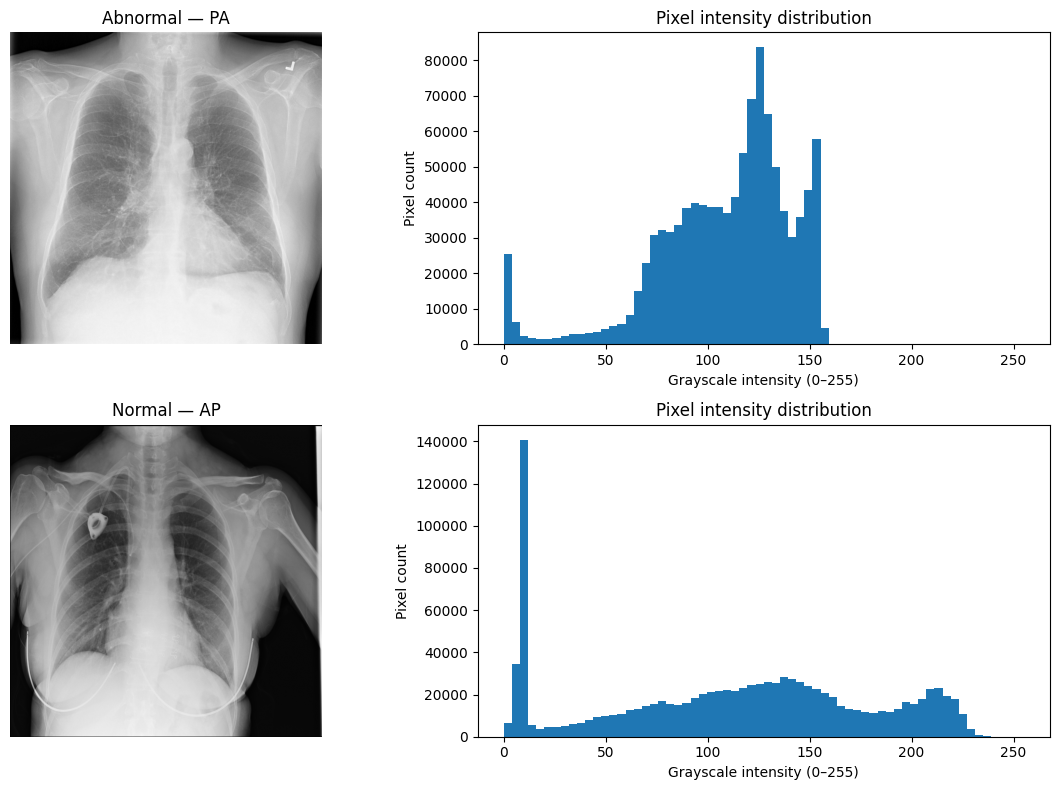

In [29]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for index, (_, row) in enumerate(sample.iterrows()):
    image_path = data_root / row["split"] / row["image_name"]

    with Image.open(image_path) as image:
        grayscale = np.asarray(image.convert("L"))

    axes[index, 0].imshow(grayscale, cmap="gray")
    axes[index, 0].set_title(f'{row["binary_label"]} — {row["view_position"]}')
    axes[index, 0].axis("off")

    axes[index, 1].hist(grayscale.ravel(), bins=64, range=(0, 255))
    axes[index, 1].set_title("Pixel intensity distribution")
    axes[index, 1].set_xlabel("Grayscale intensity (0–255)")
    axes[index, 1].set_ylabel("Pixel count")

plt.tight_layout()
plt.show()

### Histogram observations

The Abnormal PA image has most of its pixel intensities concentrated between approximately 70 and 160, with a strong peak around 125. The Normal AP image has a wider-looking distribution, with a large peak near zero and another concentration around 200–220.

These histogram shapes describe the full images, including the background and visible objects. They do not isolate lung pixels, so they should not be interpreted as a direct comparison of lung brightness.

### Pilot result and data consistency note

The two-image pilot selected one Abnormal PA image and one Normal AP image. Their mean grayscale intensities were 108.43 and 111.21, respectively. Their intensity standard deviations were 33.60 and 67.56, and their maximum observed intensities were 162 and 246.

These measurements describe only the two selected files. Since the images have different view positions and the Normal image contains a visible external object, the observed histogram differences cannot be attributed to the class label.

Both files are 1024 × 1024 pixels, while their metadata dimensions are 2021 × 2021 and 3056 × 2544. This discrepancy should be checked across a larger sample before deciding whether the files were resized, cropped, padded, or represent a different image version.

### Check image-file dimensions against metadata

The two pilot images had 1024 × 1024 file dimensions, which differed from their recorded metadata dimensions. This check compares the two sources for a small, balanced sample across class labels and view positions.

In [30]:
from PIL import Image

dimension_sample = (
    df.dropna(subset=["binary_label", "view_position"])
      .groupby(["binary_label", "view_position"], group_keys=False)
      .sample(n=5, random_state=42)
)

dimension_audit = []

for _, row in dimension_sample.iterrows():
    image_path = data_root / row["split"] / row["image_name"]

    with Image.open(image_path) as image:
        file_width, file_height = image.size

    dimension_audit.append({
        "image_name": row["image_name"],
        "binary_label": row["binary_label"],
        "view_position": row["view_position"],
        "metadata_width": row["image_width"],
        "metadata_height": row["image_height"],
        "file_width": file_width,
        "file_height": file_height,
        "dimensions_match": (
            row["image_width"] == file_width
            and row["image_height"] == file_height
        ),
    })

dimension_audit_df = pd.DataFrame(dimension_audit)
display(dimension_audit_df)

print("Dimension match count:")
display(
    dimension_audit_df
    .groupby(["binary_label", "view_position"])["dimensions_match"]
    .value_counts()
    .unstack(fill_value=0)
)

,image_name,binary_label,view_position,metadata_width,metadata_height,file_width,file_height,dimensions_match
0,00000798_025.png,Abnormal,AP,2500,2048,1024,1024,False
1,00001249_003.png,Abnormal,AP,2500,2048,1024,1024,False
2,00004435_021.png,Abnormal,AP,2500,2048,1024,1024,False
3,00018175_012.png,Abnormal,AP,2500,2048,1024,1024,False
4,00029950_002.png,Abnormal,AP,3056,2544,1024,1024,False
5,00003945_005.png,Abnormal,PA,2021,2021,1024,1024,False
6,00004937_002.png,Abnormal,PA,2500,2048,1024,1024,False
7,00018260_004.png,Abnormal,PA,2992,2991,1024,1024,False
8,00007167_000.png,Abnormal,PA,2500,2048,1024,1024,False
9,00012024_000.png,Abnormal,PA,2992,2991,1024,1024,False


Dimension match count:


dimensions_match            False
binary_label view_position       
Abnormal     AP                 5
             PA                 5
Normal       AP                 5
             PA                 5

### Pixel-level metrics on the balanced pilot sample

The following measurements are calculated from the 20 image files in the balanced pilot sample. File dimensions are used for pixel-level analysis because they describe the images actually opened. The recorded metadata dimensions are retained separately for reference.

In [31]:
import cv2
import numpy as np
from PIL import Image

pixel_results = []

for _, row in dimension_sample.iterrows():
    image_path = data_root / row["split"] / row["image_name"]

    with Image.open(image_path) as image:
        grayscale = np.asarray(image.convert("L"))

    laplacian_variance = cv2.Laplacian(
        grayscale, cv2.CV_64F
    ).var()

    pixel_results.append({
        "image_name": row["image_name"],
        "binary_label": row["binary_label"],
        "view_position": row["view_position"],
        "brightness_mean": grayscale.mean(),
        "contrast_std": grayscale.std(),
        "intensity_p05": np.percentile(grayscale, 5),
        "intensity_median": np.percentile(grayscale, 50),
        "intensity_p95": np.percentile(grayscale, 95),
        "laplacian_variance": laplacian_variance,
    })

pixel_metrics = pd.DataFrame(pixel_results)

display(
    pixel_metrics.sort_values(["view_position", "binary_label"])
                 .round(2)
)

,image_name,binary_label,view_position,brightness_mean,contrast_std,intensity_p05,intensity_median,intensity_p95,laplacian_variance
0,00000798_025.png,Abnormal,AP,113.12,50.84,12.0,125.0,184.0,142.58
1,00001249_003.png,Abnormal,AP,112.50,55.45,4.0,115.0,199.0,122.10
2,00004435_021.png,Abnormal,AP,130.85,49.71,18.0,142.0,193.0,104.77
3,00018175_012.png,Abnormal,AP,112.81,58.91,3.0,107.0,200.0,165.26
4,00029950_002.png,Abnormal,AP,112.41,59.44,13.0,123.0,196.0,137.47
10,00020349_005.png,Normal,AP,112.07,66.42,5.0,125.0,199.0,150.16
11,00020380_002.png,Normal,AP,123.18,53.70,6.0,128.0,202.0,201.00
12,00016056_005.png,Normal,AP,153.76,55.20,16.0,171.0,215.0,209.71
13,00014174_009.png,Normal,AP,155.06,58.82,29.0,159.0,230.0,196.28
14,00021460_001.png,Normal,AP,145.14,64.99,6.0,163.0,227.0,179.48


### Pilot metric summary by view and class

The table below summarizes brightness, contrast, intensity percentiles, and Laplacian variance for each view-position and class group. Each group contains five images, so these summaries are used to inspect the workflow and variability, not to make dataset-level claims.

In [32]:
pilot_summary = (
    pixel_metrics
    .groupby(["view_position", "binary_label"])
    .agg(
        image_count=("image_name", "count"),
        brightness_mean=("brightness_mean", "mean"),
        brightness_median=("brightness_mean", "median"),
        contrast_median=("contrast_std", "median"),
        intensity_p05_median=("intensity_p05", "median"),
        intensity_median_median=("intensity_median", "median"),
        intensity_p95_median=("intensity_p95", "median"),
        laplacian_mean=("laplacian_variance", "mean"),
        laplacian_median=("laplacian_variance", "median"),
    )
    .round(2)
)

display(pilot_summary)

image_count  brightness_mean  brightness_median  \
view_position binary_label                                                    
AP            Abnormal                5           116.34             112.81   
              Normal                  5           137.84             145.14   
PA            Abnormal                5           138.13             132.95   
              Normal                  5           130.39             111.96   

                            contrast_median  intensity_p05_median  \
view_position binary_label                                          
AP            Abnormal                55.45                  12.0   
              Normal                  58.82                   6.0   
PA            Abnormal                55.11                  54.0   
              Normal                  50.05                  65.0   

                            intensity_median_median  intensity_p95_median  \
view_position binary_label                                                  
AP            Abnormal                        123.0                 196.0   
              Normal                          159.0                 215.0   
PA            Abnormal                        145.0                 219.0   
              Normal                          118.0                 215.0   

                            laplacian_mean  laplacian_median  
view_position binary_label                                    
AP            Abnormal              134.43            137.47  
              Normal                187.32            196.28  
PA            Abnormal              122.00             74.01  
              Normal                 72.60             67.05

### Individual pixel-level metrics by view and class

Each point represents one image from the 20-image pilot sample. The plots show how much the measurements vary within each view and class group; they are exploratory because each group contains only five images.

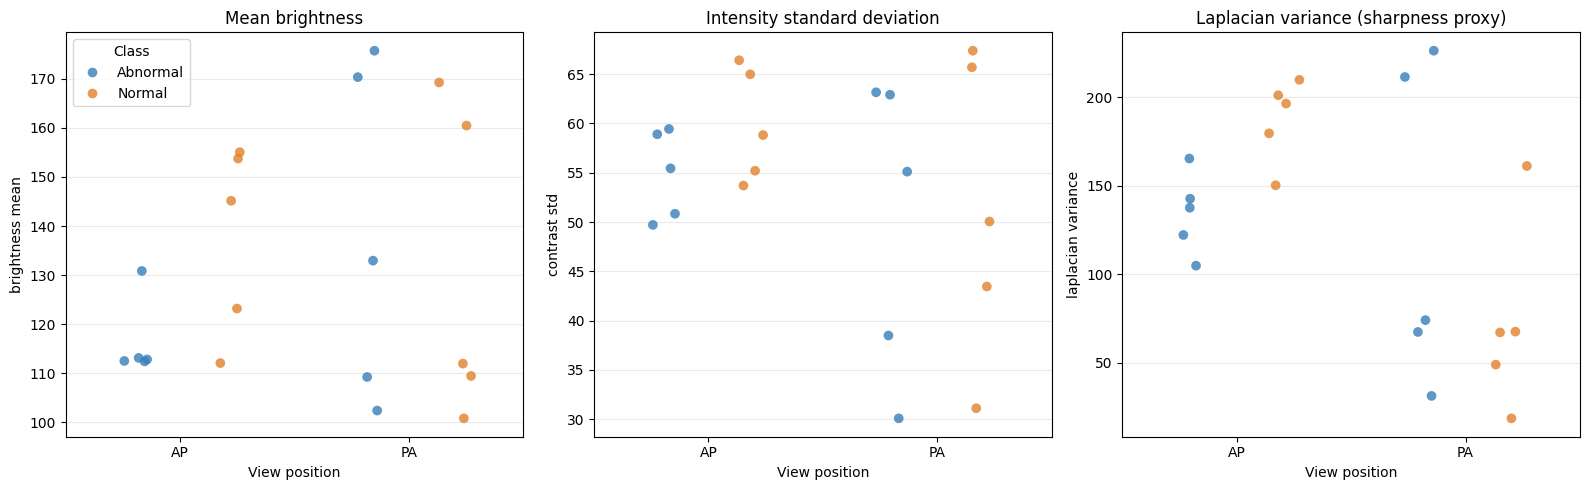

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics_to_plot = [
    ("brightness_mean", "Mean brightness"),
    ("contrast_std", "Intensity standard deviation"),
    ("laplacian_variance", "Laplacian variance (sharpness proxy)"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

palette = {
    "Abnormal": "#377eb8",
    "Normal": "#e1812c",
}

for index, (column, title) in enumerate(metrics_to_plot):
    ax = axes[index]

    sns.stripplot(
        data=pixel_metrics,
        x="view_position",
        y=column,
        hue="binary_label",
        dodge=True,
        jitter=0.15,
        size=7,
        alpha=0.8,
        palette=palette,
        ax=ax,
    )

    ax.set_title(title)
    ax.set_xlabel("View position")
    ax.set_ylabel(column.replace("_", " "))
    ax.grid(axis="y", alpha=0.25)

    if index == 0:
        ax.legend(title="Class")
    elif ax.legend_ is not None:
        ax.legend_.remove()

plt.tight_layout()
plt.show()

### Pilot observations

The brightness pattern differs between AP and PA images: the Normal AP images have a higher group mean, while the Abnormal PA images have a higher group mean. This view-dependent pattern means the pilot does not show one consistent brightness difference by class.

Contrast measurements overlap across the groups. Laplacian variance also varies substantially between individual images; in particular, the PA Abnormal mean is higher than its median, suggesting that a small number of high values may influence the mean.

These observations are based on five images per view–class group. They are not sufficient to establish class or subgroup differences; the comparisons should be repeated on a larger sample.

### Pilot interpretation

The pilot sample does not show a consistent separation between Normal and Abnormal images across AP and PA views. Brightness patterns vary by view, contrast values overlap, and Laplacian variance varies substantially between individual images.

Each view–class group contains only five images. These plots are useful for checking the measurement workflow, but they are not sufficient for class or subgroup conclusions.

In [34]:
analysis_sample = (
    df.groupby(["binary_label", "view_position"], group_keys=False)
      .sample(n=250, random_state=42)
      .copy()
)

display(
    analysis_sample
    .groupby(["view_position", "binary_label"])
    .size()
    .rename("image_count")
    .to_frame()
)

image_count
view_position binary_label             
AP            Abnormal              250
              Normal                250
PA            Abnormal              250
              Normal                250

### Pixel-level measurements on the 1,000-image sample

Brightness, contrast, intensity percentiles, and Laplacian variance are calculated for each sampled image. The metadata fields are retained so the measurements can later be compared by class, age, sex, and view position.

In [35]:
from tqdm.auto import tqdm
import cv2
import numpy as np
from PIL import Image

pixel_results_1k = []

for _, row in tqdm(
    analysis_sample.iterrows(),
    total=len(analysis_sample)
):
    image_path = data_root / row["split"] / row["image_name"]

    with Image.open(image_path) as image:
        grayscale = np.asarray(image.convert("L"))

    pixel_results_1k.append({
        "image_name": row["image_name"],
        "binary_label": row["binary_label"],
        "view_position": row["view_position"],
        "patient_age": row["patient_age"],
        "patient_sex": row["patient_sex"],
        "file_width": grayscale.shape[1],
        "file_height": grayscale.shape[0],
        "brightness_mean": grayscale.mean(),
        "contrast_std": grayscale.std(),
        "intensity_p05": np.percentile(grayscale, 5),
        "intensity_median": np.percentile(grayscale, 50),
        "intensity_p95": np.percentile(grayscale, 95),
        "laplacian_variance": cv2.Laplacian(
            grayscale, cv2.CV_64F
        ).var(),
    })

pixel_metrics_1k = pd.DataFrame(pixel_results_1k)

print("Images measured:", len(pixel_metrics_1k))
display(pixel_metrics_1k.head())

  0%|          | 0/1000 [00:00<?, ?it/s]

Images measured: 1000


,image_name,binary_label,view_position,patient_age,patient_sex,file_width,file_height,brightness_mean,contrast_std,intensity_p05,intensity_median,intensity_p95,laplacian_variance
0,00000798_025.png,Abnormal,AP,64,F,1024,1024,113.121041,50.839867,12.0,125.0,184.0,142.577012
1,00001249_003.png,Abnormal,AP,40,M,1024,1024,112.499457,55.448917,4.0,115.0,199.0,122.099027
2,00004435_021.png,Abnormal,AP,28,F,1024,1024,130.846219,49.711986,18.0,142.0,193.0,104.766929
3,00018175_012.png,Abnormal,AP,55,M,1024,1024,112.811107,58.906192,3.0,107.0,200.0,165.259355
4,00029950_002.png,Abnormal,AP,36,F,1024,1024,112.407165,59.444209,13.0,123.0,196.0,137.470799


### Save the sampled image metrics

The image measurements have been computed for the 1,000-image sample. Save them so the analysis can continue without reopening the image files.

In [36]:
from pathlib import Path

results_dir = Path("/content/drive/MyDrive/NIH_ChestXray/EDA_Results")
results_dir.mkdir(parents=True, exist_ok=True)

metrics_path = results_dir / "pixel_metrics_1k.csv"
pixel_metrics_1k.to_csv(metrics_path, index=False)

print("Saved:", metrics_path)
print("Rows saved:", len(pixel_metrics_1k))

Saved: /content/drive/MyDrive/NIH_ChestXray/EDA_Results/pixel_metrics_1k.csv
Rows saved: 1000


### Image quality metrics by class and view position

The following table summarizes the image-level measurements by class and view position. Each group contains 250 images. Medians and interquartile ranges help describe the typical values and their spread.

In [37]:
metric_columns = [
    "brightness_mean",
    "contrast_std",
    "intensity_median",
    "intensity_p95",
    "laplacian_variance",
]

summary_rows = []

for (view, label), group in pixel_metrics_1k.groupby(
    ["view_position", "binary_label"]
):
    row = {
        "view_position": view,
        "binary_label": label,
        "image_count": len(group),
    }

    for column in metric_columns:
        row[f"{column}_median"] = group[column].median()
        row[f"{column}_q1"] = group[column].quantile(0.25)
        row[f"{column}_q3"] = group[column].quantile(0.75)

    summary_rows.append(row)

class_view_summary = pd.DataFrame(summary_rows).round(2)
display(class_view_summary)

,view_position,binary_label,image_count,brightness_mean_median,brightness_mean_q1,brightness_mean_q3,contrast_std_median,contrast_std_q1,contrast_std_q3,intensity_median_median,intensity_median_q1,intensity_median_q3,intensity_p95_median,intensity_p95_q1,intensity_p95_q3,laplacian_variance_median,laplacian_variance_q1,laplacian_variance_q3
0,AP,Abnormal,250,119.45,109.61,132.35,55.13,49.58,59.69,124.0,112.00,140.75,201.0,191.00,212.0,154.65,120.55,188.41
1,AP,Normal,250,121.79,113.39,141.31,54.04,48.98,58.82,128.0,118.00,151.00,203.0,192.00,215.0,159.68,111.80,199.03
2,PA,Abnormal,250,124.54,110.89,136.54,66.06,61.62,70.29,129.5,115.25,148.00,223.5,216.00,228.0,69.45,57.79,86.39
3,PA,Normal,250,124.94,111.82,154.87,64.22,55.63,68.32,130.0,116.00,169.00,223.0,214.25,228.0,65.72,49.56,81.60


### Preliminary class comparison by view

Within each view position, the class medians are close relative to the spread of values. For example, median brightness is 119.45 for Abnormal and 121.79 for Normal in AP images, and 124.54 and 124.94, respectively, in PA images. The interquartile ranges overlap across most measurements.

Laplacian variance differs more between view positions than between classes in this sample: its median is approximately 155–160 for AP images and 66–69 for PA images. This suggests an association between view position and this sharpness proxy. It does not establish that one view is intrinsically sharper, because Laplacian variance is also affected by image content and processing.

Each class–view group contains 250 images. These descriptive results do not establish statistical significance or causation.

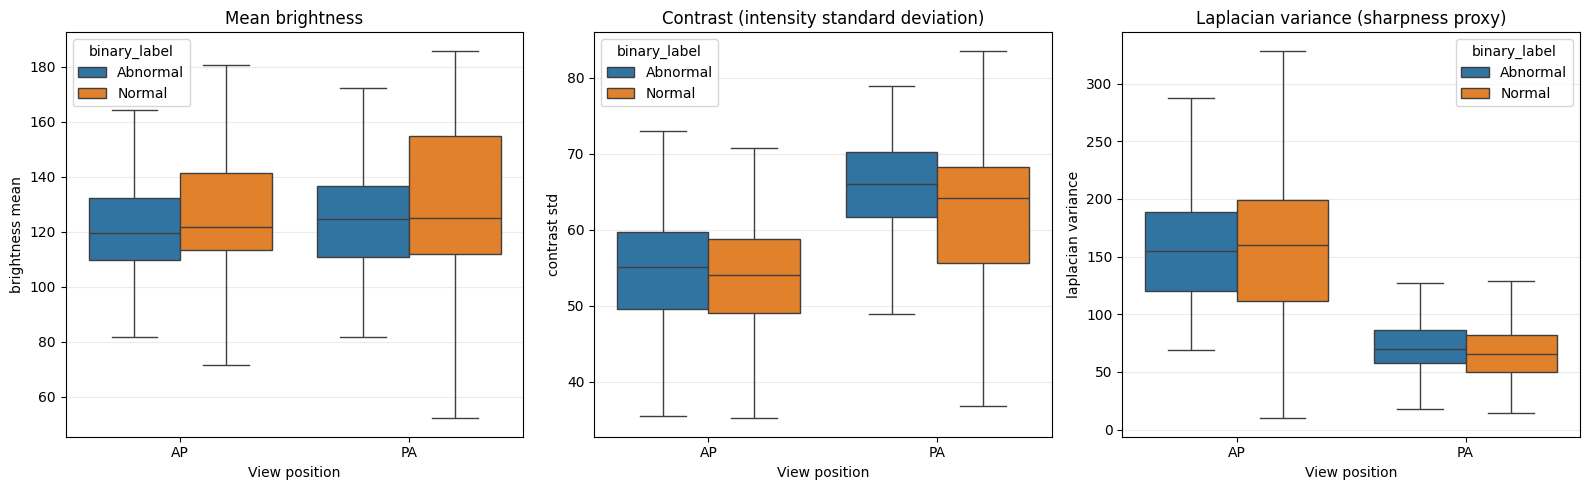

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_metrics = [
    ("brightness_mean", "Mean brightness"),
    ("contrast_std", "Contrast (intensity standard deviation)"),
    ("laplacian_variance", "Laplacian variance (sharpness proxy)"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (column, title) in zip(axes, plot_metrics):
    sns.boxplot(
        data=pixel_metrics_1k,
        x="view_position",
        y=column,
        hue="binary_label",
        showfliers=False,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("View position")
    ax.set_ylabel(column.replace("_", " "))
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### Class comparison by view: visual summary

The Normal and Abnormal distributions overlap substantially within both AP and PA views for brightness, contrast, and Laplacian variance. In contrast, Laplacian variance is visibly higher in AP than in PA images for both classes.

In this sample, view position appears more strongly associated with the sharpness proxy than class label. This does not establish causation or prove that AP images are sharper; image content and processing can also affect Laplacian variance. View position should therefore be considered when interpreting later class and demographic comparisons.

### Image quality metrics by recorded sex and view

The following table compares image metrics across recorded sex and class within each view position. Stratifying by view helps account for the large AP–PA difference observed in Laplacian variance.


In [39]:
sex_summary = (
    pixel_metrics_1k
    .groupby(
        ["view_position", "patient_sex", "binary_label"],
        dropna=False
    )
    .agg(
        image_count=("image_name", "count"),
        brightness_median=("brightness_mean", "median"),
        brightness_q1=("brightness_mean", lambda values: values.quantile(0.25)),
        brightness_q3=("brightness_mean", lambda values: values.quantile(0.75)),
        contrast_median=("contrast_std", "median"),
        laplacian_median=("laplacian_variance", "median"),
    )
    .round(2)
)

display(sex_summary)

image_count  brightness_median  \
view_position patient_sex binary_label                                   
AP            F           Abnormal              111             114.35   
                          Normal                 92             117.86   
              M           Abnormal              139             121.62   
                          Normal                158             123.81   
PA            F           Abnormal              115             119.20   
                          Normal                114             126.42   
              M           Abnormal              135             128.37   
                          Normal                136             123.84   

                                        brightness_q1  brightness_q3  \
view_position patient_sex binary_label                                 
AP            F           Abnormal             106.41         131.07   
                          Normal               111.15         142.11   
              M           Abnormal             112.20         133.84   
                          Normal               114.95         140.48   
PA            F           Abnormal             107.63         134.36   
                          Normal               108.66         154.87   
              M           Abnormal             118.31         142.24   
                          Normal               112.05         151.51   

                                        contrast_median  laplacian_median  
view_position patient_sex binary_label                                     
AP            F           Abnormal                56.11            152.01  
                          Normal                  56.22            159.92  
              M           Abnormal                53.24            157.69  
                          Normal                  52.73            159.20  
PA            F           Abnormal                66.89             69.07  
                          Normal                  64.38             68.69  
              M           Abnormal                65.59             69.54  
                          Normal                  64.14             64.78

### Preliminary comparison by recorded sex

Within each view position, the Normal and Abnormal medians are generally close, and the direction of the brightness difference is not consistent across sex and view groups. Contrast medians are similar, and Laplacian medians show no clear, consistent separation by sex or class.

These descriptive results do not show a strong sex-related pattern in this sample. They do not establish that sex has no association with image quality; the sample is limited, and other factors such as age and acquisition characteristics may also contribute.

In [40]:
pixel_metrics_1k["age_group"] = pd.cut(
    pixel_metrics_1k["patient_age"],
    bins=[0, 18, 40, 60, 120],
    labels=["1–18", "19–40", "41–60", "61–120"]
).astype("object")

pixel_metrics_1k.loc[
    pixel_metrics_1k["patient_age"].eq(0),
    "age_group"
] = "Recorded age 0"

pixel_metrics_1k.loc[
    pixel_metrics_1k["patient_age"].isna(),
    "age_group"
] = "Missing"

age_summary_1k = (
    pixel_metrics_1k
    .groupby(
        ["age_group", "view_position", "binary_label"],
        dropna=False
    )
    .agg(
        image_count=("image_name", "count"),
        brightness_median=("brightness_mean", "median"),
        contrast_median=("contrast_std", "median"),
        laplacian_median=("laplacian_variance", "median"),
    )
    .round(2)
)

display(age_summary_1k)

image_count  brightness_median  \
age_group view_position binary_label                                   
19–40     AP            Abnormal               73             118.80   
                        Normal                 78             118.20   
          PA            Abnormal               53             123.32   
                        Normal                 74             125.85   
1–18      AP            Abnormal               17             101.85   
                        Normal                 14             114.83   
          PA            Abnormal                5             124.26   
                        Normal                 12             112.08   
41–60     AP            Abnormal               96             121.06   
                        Normal                110             127.16   
          PA            Abnormal              118             123.50   
                        Normal                108             124.94   
61–120    AP            Abnormal               64             120.83   
                        Normal                 48             125.30   
          PA            Abnormal               74             126.09   
                        Normal                 56             124.88   

                                      contrast_median  laplacian_median  
age_group view_position binary_label                                     
19–40     AP            Abnormal                55.59            146.52  
                        Normal                  53.38            158.43  
          PA            Abnormal                66.05             67.07  
                        Normal                  64.15             67.57  
1–18      AP            Abnormal                67.50            124.55  
                        Normal                  58.14            158.03  
          PA            Abnormal                69.61             96.27  
                        Normal                  65.86             65.74  
41–60     AP            Abnormal                54.50            155.65  
                        Normal                  53.28            147.61  
          PA            Abnormal                66.08             71.12  
                        Normal                  64.20             66.14  
61–120    AP            Abnormal                52.77            165.76  
                        Normal                  55.47            181.57  
          PA            Abnormal                65.91             69.03  
                        Normal                  64.34             62.46

### Preliminary age-group comparison

Within the larger age groups, class differences in brightness, contrast, and Laplacian variance vary in direction and are generally small relative to the spread reported in earlier comparisons. The table does not show a consistent age-specific class pattern.

Laplacian medians are generally higher for AP than PA images across age groups, consistent with the view-position pattern seen earlier. This remains a descriptive association with a sharpness proxy, not proof that AP images are sharper.

Some younger age-by-view-by-class groups contain few images, including only five Abnormal PA images in the 1–18 group. These small groups should not be used to support firm conclusions.

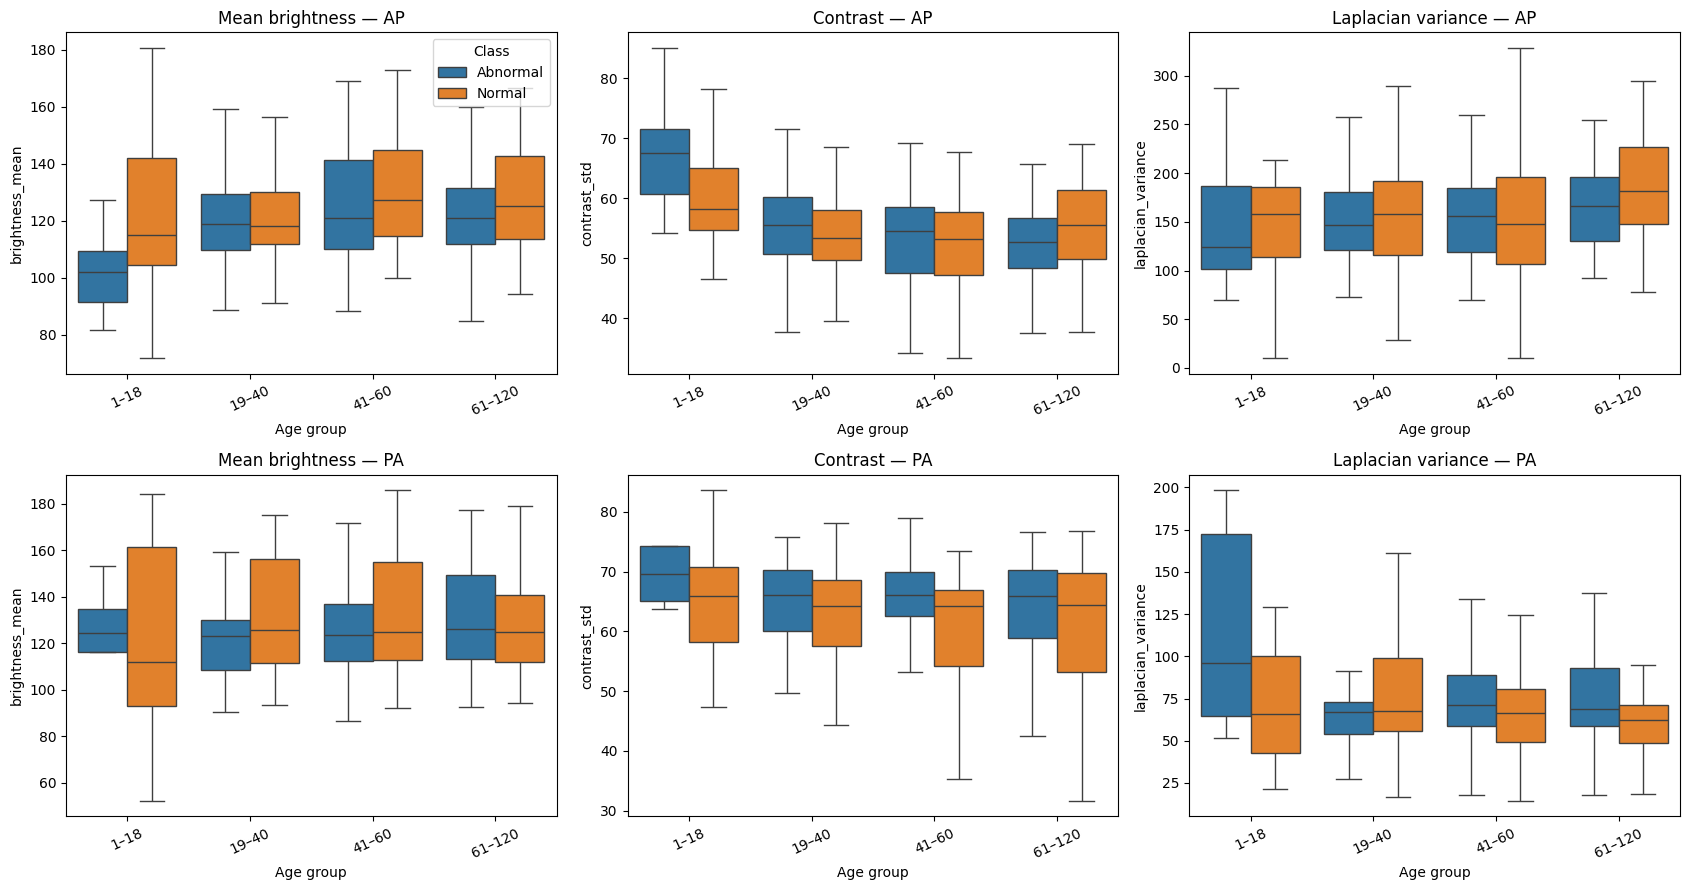

In [42]:
age_order = [
    group for group in [
        "1–18", "19–40", "41–60", "61–120",
        "Recorded age 0", "Missing"
    ]
    if group in pixel_metrics_1k["age_group"].astype(str).unique()
]

plot_metrics = [
    ("brightness_mean", "Mean brightness"),
    ("contrast_std", "Contrast"),
    ("laplacian_variance", "Laplacian variance"),
]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))

for row_index, view in enumerate(["AP", "PA"]):
    view_data = pixel_metrics_1k[
        pixel_metrics_1k["view_position"] == view
    ]

    for column_index, (metric, title) in enumerate(plot_metrics):
        ax = axes[row_index, column_index]

        sns.boxplot(
            data=view_data,
            x="age_group",
            y=metric,
            hue="binary_label",
            order=age_order,
            showfliers=False,
            ax=ax,
        )

        ax.set_title(f"{title} — {view}")
        ax.set_xlabel("Age group")
        ax.tick_params(axis="x", rotation=25)

        if row_index == 0 and column_index == 0:
            ax.legend(title="Class")
        elif ax.legend_ is not None:
            ax.legend_.remove()

plt.tight_layout()
plt.show()

### Age-group plot observations

The plots do not show a consistent change in brightness, contrast, or Laplacian variance across increasing age groups. Differences between Normal and Abnormal groups also vary in direction across age and view subgroups.

The 1–18 age group has relatively few images, particularly the Abnormal PA subgroup (n = 5). Its box plots should therefore be interpreted cautiously. These are descriptive comparisons from the sampled images, not evidence of an age-related effect.

In [43]:
for subgroup in ["age_group", "patient_sex"]:
    print(f"Metrics by {subgroup}, view, and class")

    subgroup_summary = (
        pixel_metrics_1k
        .groupby(
            [subgroup, "view_position", "binary_label"],
            dropna=False
        )
        .agg(
            image_count=("image_name", "count"),
            brightness_median=("brightness_mean", "median"),
            contrast_median=("contrast_std", "median"),
            intensity_median=("intensity_median", "median"),
            intensity_p95=("intensity_p95", "median"),
            laplacian_median=("laplacian_variance", "median"),
        )
        .round(2)
    )

    display(subgroup_summary)

Metrics by age_group, view, and class


image_count  brightness_median  \
age_group view_position binary_label                                   
19–40     AP            Abnormal               73             118.80   
                        Normal                 78             118.20   
          PA            Abnormal               53             123.32   
                        Normal                 74             125.85   
1–18      AP            Abnormal               17             101.85   
                        Normal                 14             114.83   
          PA            Abnormal                5             124.26   
                        Normal                 12             112.08   
41–60     AP            Abnormal               96             121.06   
                        Normal                110             127.16   
          PA            Abnormal              118             123.50   
                        Normal                108             124.94   
61–120    AP            Abnormal               64             120.83   
                        Normal                 48             125.30   
          PA            Abnormal               74             126.09   
                        Normal                 56             124.88   

                                      contrast_median  intensity_median  \
age_group view_position binary_label                                      
19–40     AP            Abnormal                55.59             123.0   
                        Normal                  53.38             122.5   
          PA            Abnormal                66.05             125.0   
                        Normal                  64.15             134.0   
1–18      AP            Abnormal                67.50             114.0   
                        Normal                  58.14             124.5   
          PA            Abnormal                69.61             136.0   
                        Normal                  65.86             122.0   
41–60     AP            Abnormal                54.50             125.0   
                        Normal                  53.28             134.0   
          PA            Abnormal                66.08             130.0   
                        Normal                  64.20             129.0   
61–120    AP            Abnormal                52.77             125.0   
                        Normal                  55.47             128.0   
          PA            Abnormal                65.91             134.5   
                        Normal                  64.34             130.0   

                                      intensity_p95  laplacian_median  
age_group view_position binary_label                                   
19–40     AP            Abnormal              201.0            146.52  
                        Normal                199.5            158.43  
          PA            Abnormal              222.0             67.07  
                        Normal                221.5             67.57  
1–18      AP            Abnormal              194.0            124.55  
                        Normal                202.0            158.03  
          PA            Abnormal              220.0             96.27  
                        Normal                221.0             65.74  
41–60     AP            Abnormal              203.0            155.65  
                        Normal                204.5            147.61  
          PA            Abnormal              224.0             71.12  
                        Normal                224.0             66.14  
61–120    AP            Abnormal              204.0            165.76  
                        Normal                207.0            181.57  
          PA            Abnormal              226.0             69.03  
                        Normal                224.0             62.46

Metrics by patient_sex, view, and class


image_count  brightness_median  \
patient_sex view_position binary_label                                   
F           AP            Abnormal              111             114.35   
                          Normal                 92             117.86   
            PA            Abnormal              115             119.20   
                          Normal                114             126.42   
M           AP            Abnormal              139             121.62   
                          Normal                158             123.81   
            PA            Abnormal              135             128.37   
                          Normal                136             123.84   

                                        contrast_median  intensity_median  \
patient_sex view_position binary_label                                      
F           AP            Abnormal                56.11             121.0   
                          Normal                  56.22             124.0   
            PA            Abnormal                66.89             121.0   
                          Normal                  64.38             135.0   
M           AP            Abnormal                53.24             126.0   
                          Normal                  52.73             130.0   
            PA            Abnormal                65.59             135.0   
                          Normal                  64.14             128.0   

                                        intensity_p95  laplacian_median  
patient_sex view_position binary_label                                   
F           AP            Abnormal              198.0            152.01  
                          Normal                203.5            159.92  
            PA            Abnormal              220.0             69.07  
                          Normal                221.0             68.69  
M           AP            Abnormal              204.0            157.69  
                          Normal                203.0            159.20  
            PA            Abnormal              224.0             69.54  
                          Normal                224.0             64.78

### Image quality metrics by sex, class, and view

These plots compare brightness, contrast, and Laplacian variance across recorded-sex groups. AP and PA are shown separately to account for the view-related differences observed earlier.

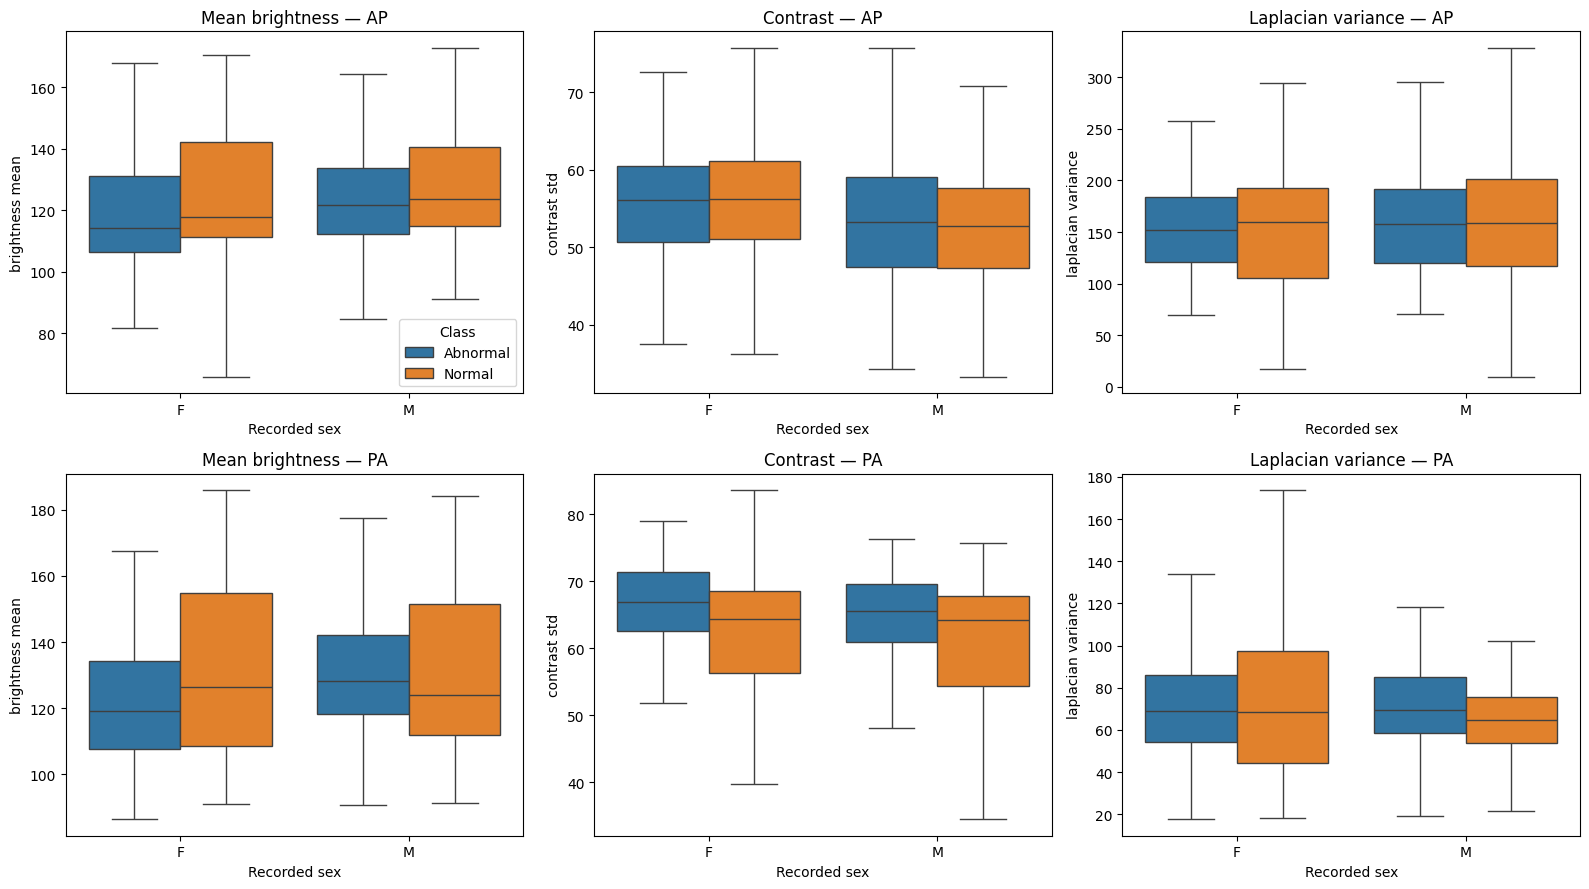

In [44]:
plot_metrics = [
    ("brightness_mean", "Mean brightness"),
    ("contrast_std", "Contrast"),
    ("laplacian_variance", "Laplacian variance"),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for row_index, view in enumerate(["AP", "PA"]):
    view_data = pixel_metrics_1k[
        pixel_metrics_1k["view_position"] == view
    ]

    for column_index, (metric, title) in enumerate(plot_metrics):
        ax = axes[row_index, column_index]

        sns.boxplot(
            data=view_data,
            x="patient_sex",
            y=metric,
            hue="binary_label",
            order=["F", "M"],
            showfliers=False,
            ax=ax,
        )

        ax.set_title(f"{title} — {view}")
        ax.set_xlabel("Recorded sex")
        ax.set_ylabel(metric.replace("_", " "))

        if row_index == 0 and column_index == 0:
            ax.legend(title="Class")
        elif ax.legend_ is not None:
            ax.legend_.remove()

plt.tight_layout()
plt.show()

### Sex subgroup plot observations

The Normal and Abnormal distributions overlap substantially across recorded-sex groups. In AP images, median brightness is slightly higher for Normal images for both females and males. In PA images, the direction differs by sex: Normal brightness is higher among females, while Abnormal brightness is higher among males.

Contrast and Laplacian variance also show no consistent separation by sex and class. The AP–PA difference in Laplacian variance remains more visible than the differences between sex or class groups. These plots reinforce the earlier table and do not establish a sex-related image-quality pattern.

## 3.3 Evidence-Based Findings

Pixel-level findings below are based on a stratified sample of 1,000 images: 250 images in each class–view group. Metadata dimensions were analyzed separately. These results are descriptive; no statistical significance tests were performed.

### Finding 1: View position is associated with image-quality measurements

**Observation:** AP and PA images show different distributions for several pixel-level measurements, especially Laplacian variance and upper-end intensity.

**Evidence:** Median Laplacian variance is 154.65 for Abnormal AP and 159.68 for Normal AP, compared with 69.45 for Abnormal PA and 65.72 for Normal PA. The median per-image 95th-percentile intensity is 201–203 for AP and approximately 223 for PA.

**Implication:** View position and acquisition characteristics may influence measurements available to a model, creating a potential shortcut unrelated to the target finding.

**Recommendation:** Report image-quality results and future model performance separately for AP and PA. Interpret Laplacian variance as a sharpness proxy, not a direct or definitive blur measurement.

### Finding 2: The measured image-quality features do not clearly separate Normal and Abnormal images

**Observation:** Within AP and PA views, class medians are close relative to the spread of values, and the plotted distributions overlap.

**Evidence:** Median brightness is 119.45 for Abnormal AP versus 121.79 for Normal AP, and 124.54 versus 124.94 for PA. Median contrast is 55.13 versus 54.04 in AP and 66.06 versus 64.22 in PA. Laplacian medians are also close within each view.

**Implication:** This sample does not show a consistent image-quality pattern that separates the two classes.

**Recommendation:** Do not apply class-specific preprocessing based on these results. Reassess image-quality patterns alongside model evaluation.

### Finding 3: Age and recorded-sex comparisons show no consistent class pattern

**Observation:** Differences in brightness, contrast, and Laplacian variance vary in direction across age, sex, and view groups.

**Evidence:** Among PA images, median brightness is higher for Normal than Abnormal images among females (126.42 vs. 119.20), but higher for Abnormal than Normal images among males (128.37 vs. 123.84). The age comparisons likewise show no consistent direction. The 1–18 Abnormal PA subgroup contains only five images.

**Implication:** These comparisons do not establish a consistent age- or sex-related image-quality difference. Small subgroup counts make some estimates unstable.

**Recommendation:** Report subgroup counts with the comparisons, interpret small groups cautiously, and evaluate model performance by age and recorded sex once model results are available.

### Finding 4: Metadata dimensions differ from the dimensions of inspected image files

**Observation:** In a balanced audit of 20 files, every inspected PNG measured 1024 × 1024 pixels, while its metadata dimensions differed.

**Evidence:** The metadata dimensions varied across the audited images, including examples such as 2500 × 2048 and 3056 × 2544, while the corresponding files were 1024 × 1024.

**Implication:** The metadata dimensions and the image files used for pixel-level analysis appear to describe different image representations.

**Recommendation:** Report metadata dimensions separately from inspected file dimensions. Confirm the image preparation or resizing process before drawing conclusions about the resolution and aspect ratio of the files used by the model.